# Phân tích cảm xúc đánh giá phim IMDB
## So sánh LSTM, mạng neural truyền thẳng, SVM và Logistic Regression

Phân loại đánh giá phim thành hai lớp: `0` (tiêu cực) và `1` (tích cực). Thí nghiệm sử dụng LSTM và ba mô hình đối chứng: MLP, Linear SVM, Logistic Regression.

Nội dung gồm cơ sở lý thuyết, xử lý dữ liệu, huấn luyện, đánh giá và phân tích lỗi.

**Cách chạy:** mở bằng Jupyter hoặc Google Colab, chọn **Runtime → Run all**. GPU giúp LSTM chạy nhanh hơn nhưng không bắt buộc. Lần đầu cần Internet để tải hai tệp parquet IMDB từ Hugging Face. Mã sử dụng PyTorch. Kết quả được ghi trong thư mục `results/`.

In [1]:
# Bỏ dấu # ở dòng dưới nếu môi trường chưa có thư viện; sau đó khởi động lại kernel.
# %pip install "torch>=2.2,<3" "scikit-learn>=1.4,<2" "numpy>=1.26,<3" "pandas>=2.1,<3" "matplotlib>=3.8,<4" "pyarrow>=15"
import os, re, html, time, copy, random, json, tarfile, hashlib, platform
from pathlib import Path
from urllib.request import urlretrieve
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay)
from IPython.display import display, Markdown

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(min(4, os.cpu_count() or 1))
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT = Path('results'); OUT.mkdir(exist_ok=True)
print({'Python': platform.python_version(), 'PyTorch': torch.__version__,
       'sklearn': sklearn.__version__, 'device': str(DEVICE), 'seed': SEED})

{'Python': '3.13.5', 'PyTorch': '2.14.0+cpu', 'sklearn': '1.9.1', 'device': 'cpu', 'seed': 42}


## 1. Dữ liệu và thiết kế thí nghiệm

[Large Movie Review Dataset của Stanford](https://ai.stanford.edu/~amaas/data/sentiment/) có **50.000 đánh giá gán nhãn**, chia sẵn 25.000 train và 25.000 test, cân bằng hai lớp. Bộ phát hành còn có dữ liệu không nhãn; bài này không dùng phần đó.

Tách phân tầng 20% tập train gốc làm validation: **20.000 train / 5.000 validation / 25.000 test**. Cả bốn mô hình dùng cùng chỉ mục. Chỉ fit từ vựng, IDF và tham số trên train; chọn siêu tham số và checkpoint bằng validation. Test chỉ dùng khi mọi mô hình đã được chọn xong. Không tái huấn luyện trên train+validation trong thí nghiệm này.

Hai cách biểu diễn: TF–IDF unigram/bigram cho Logistic Regression, SVM và MLP; chuỗi token cho LSTM. Đây là so sánh các **pipeline** trên cùng dữ liệu, không phải thí nghiệm chỉ thay kiến trúc: TF–IDF dùng toàn bộ review, còn LSTM giới hạn 256 token đầu để phù hợp tài nguyên. Giới hạn này được đo và thảo luận bên dưới.

In [2]:
DATA = Path('data'); DATA.mkdir(exist_ok=True)
frames, digest = {}, {}
for split in ['train','test']:
    path = DATA / f'{split}.parquet'
    if not path.exists():
        url = (f'https://huggingface.co/datasets/stanfordnlp/imdb/resolve/main/'
               f'plain_text/{split}-00000-of-00001.parquet')
        temporary = path.with_suffix('.download')
        urlretrieve(url,temporary)
        temporary.replace(path)
    digest[split] = hashlib.sha256(path.read_bytes()).hexdigest()
    frames[split] = pd.read_parquet(path)[['text','label']]
    frames[split]['id'] = [f'{split}/{i}' for i in range(len(frames[split]))]
    assert len(frames[split]) == 25000
    assert frames[split]['label'].value_counts().to_dict() == {0:12500, 1:12500}
print('SHA256 dữ liệu:',digest)
raw_train, test = frames['train'], frames['test']
train, val = train_test_split(raw_train, test_size=0.2, random_state=SEED,
                             stratify=raw_train.label)
train, val = train.reset_index(drop=True), val.reset_index(drop=True)
assert set(train.id).isdisjoint(val.id)
assert set(raw_train.id).isdisjoint(test.id)
display(pd.DataFrame({s: f.label.value_counts().sort_index()
                     for s, f in [('train',train), ('validation',val), ('test',test)]}))

SHA256 dữ liệu: {'train': 'db47d16b5c297cc0dd625e519c81319c24c9149e70e8496de5475f6fa928342c', 'test': 'b52e26e2f872d282ffac460bf9770b25ac6f102cda0e6ca7158df98c94e8b3da'}


,train,validation,test
label,,,
0,10000,2500,12500
1,10000,2500,12500


## 2. Tiền xử lý và khám phá dữ liệu

Giải mã HTML, xóa thẻ HTML, chuyển chữ thường và gộp khoảng trắng. Giữ từ phủ định (`not`, `no`, `never`), không loại stopword và không stemming. TF–IDF lấy tối đa 20.000 đặc trưng với `min_df=2`, `sublinear_tf=True`; LSTM xây từ vựng riêng trên chính tập train, tối đa 20.000 token gồm PAD và UNK.

,Số token / review (train)
count,20000.000000
mean,233.346500
std,172.999483
min,10.000000
50%,175.000000
90%,456.100000
95%,593.000000
max,2492.000000


Tỷ lệ review train bị cắt ở 256 token: 29.08%


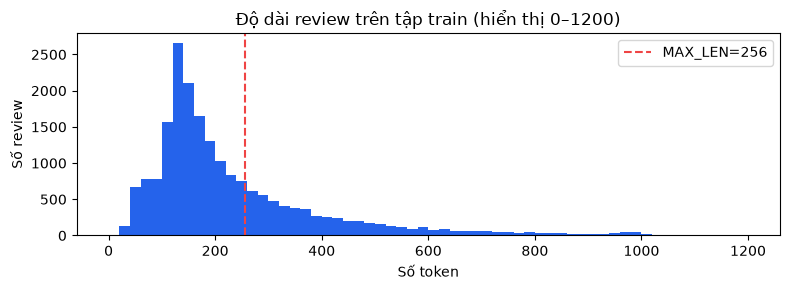

,clean,label
10650,farrah fawcett gives the best performance by a...,1
2041,i think the show had a pretty good concept to ...,0


In [3]:
def clean_text(text):
    text = html.unescape(text)
    text = re.sub(r'<[^>]+>', ' ', text)
    return re.sub(r'\s+', ' ', text.lower()).strip()

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|[!?]", text)

for frame in (train, val, test): frame['clean'] = frame.text.map(clean_text)
lengths = train.clean.map(lambda s: len(tokenize(s)))
MAX_LEN, VOCAB_SIZE = 256, 20000
display(lengths.describe(percentiles=[.5,.9,.95]).to_frame('Số token / review (train)'))
print(f'Tỷ lệ review train bị cắt ở {MAX_LEN} token: {(lengths > MAX_LEN).mean():.2%}')
plt.figure(figsize=(8,3))
plt.hist(lengths, bins=60, range=(0,1200), color='#2563eb')
plt.axvline(MAX_LEN, color='#ef4444', linestyle='--', label=f'MAX_LEN={MAX_LEN}')
plt.xlabel('Số token'); plt.ylabel('Số review'); plt.title('Độ dài review trên tập train (hiển thị 0–1200)')
plt.legend(); plt.tight_layout(); plt.show()
display(train[['clean','label']].sample(2, random_state=SEED))

## 3. Cơ sở các mô hình

* **Logistic Regression:** $p(y=1\mid x)=\sigma(w^Tx+b)$, học bằng log loss có điều chuẩn L2. Đây là mô hình tuyến tính, không có tầng ẩn.
* **Linear SVM:** học siêu phẳng phân tách bằng squared hinge loss và điều chuẩn L2. Dùng điểm `decision_function` để tính ROC-AUC; điểm này không phải xác suất.
* **MLP (mạng neural cơ bản):** `TF–IDF → Linear(20.000 thực tế hoặc ít hơn, 64) → ReLU → Dropout(0.5) → Linear(64,1)`. Học quan hệ phi tuyến nhưng không biểu diễn tuần tự token.
* **LSTM:** `Embedding(20.000 thực tế hoặc ít hơn,64) → LSTM(64,64) → Dropout(0.3) → Linear(64,1)`. Lấy trạng thái ẩn tại token cuối có thật, bỏ qua phần PAD ở đuôi khi phân loại.

Với $z_t=[h_{t-1},x_t]$, LSTM có các cổng:

$$f_t=\sigma(W_fz_t+b_f),\quad i_t=\sigma(W_iz_t+b_i),\quad o_t=\sigma(W_oz_t+b_o)$$
$$\tilde c_t=\tanh(W_cz_t+b_c),\quad c_t=f_t\odot c_{t-1}+i_t\odot\tilde c_t,\quad h_t=o_t\odot\tanh(c_t).$$

Trạng thái ô nhớ và các cổng hỗ trợ lưu thông tin qua nhiều bước thời gian, giảm khó khăn gradient so với RNN thường. Điều này không bảo đảm LSTM luôn hơn TF–IDF trên IMDB.

**Chọn mô hình:** LR và SVM thử `C ∈ {0.5, 2.0}` theo validation F1. MLP tối đa 8 epoch; LSTM tối đa 10 epoch, Adam `lr=0.001`, batch 128, binary cross entropy với logits. Cả hai dừng sớm sau 2 epoch không cải thiện validation F1 và khôi phục checkpoint tốt nhất. LSTM clip chuẩn gradient ở 1.0. Ngưỡng phân lớp cố định 0.5 cho xác suất (0 cho logits/điểm SVM).

In [4]:
start = time.perf_counter()
tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1,2), min_df=2,
                        sublinear_tf=True, dtype=np.float32)
Xtr = tfidf.fit_transform(train.clean)
Xv = tfidf.transform(val.clean)
tfidf_seconds = time.perf_counter() - start
ytr, yv, ytest = train.label.to_numpy(), val.label.to_numpy(), test.label.to_numpy()
models, fit_times, selection, histories = {}, {}, [], {}
for name, cls in [('Logistic Regression',LogisticRegression), ('Linear SVM',LinearSVC)]:
    best_score, best_model = -1, None
    start = time.perf_counter()
    for C in [0.5, 2.0]:
        model = cls(C=C, max_iter=2000, random_state=SEED)
        model.fit(Xtr,ytr)
        score = f1_score(yv,model.predict(Xv))
        selection.append({'model':name,'C':C,'validation_F1':score})
        if score > best_score: best_score, best_model = score, model
    models[name] = best_model
    fit_times[name] = time.perf_counter()-start
display(pd.DataFrame(selection))
print('Số đặc trưng TF–IDF:', Xtr.shape[1], '| thời gian fit/transform train+val:', round(tfidf_seconds,2),'s')

,model,C,validation_F1
0,Logistic Regression,0.5,0.894612
1,Logistic Regression,2.0,0.902062
2,Linear SVM,0.5,0.905758
3,Linear SVM,2.0,0.894338


Số đặc trưng TF–IDF: 20000 | thời gian fit/transform train+val: 11.34 s


In [5]:
counter = Counter(t for s in train.clean for t in tokenize(s))
vocab = {'<PAD>':0, '<UNK>':1}
vocab.update({w:i+2 for i,(w,_) in enumerate(counter.most_common(VOCAB_SIZE-2))})
def encode(texts):
    arr = np.zeros((len(texts),MAX_LEN),dtype=np.int64)
    lens = np.ones(len(texts),dtype=np.int64)
    for i,s in enumerate(texts):
        ids = [vocab.get(t,1) for t in tokenize(s)[:MAX_LEN]] or [1]
        arr[i,:len(ids)], lens[i] = ids,len(ids)
    return arr,lens
seq_tr,len_tr = encode(train.clean)
seq_v,len_v = encode(val.clean)

class MLP(nn.Module):
    def __init__(self,n_features):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_features,64),nn.ReLU(),nn.Dropout(.5),nn.Linear(64,1))
    def forward(self,x,lengths=None): return self.net(x).squeeze(1)

class SentimentLSTM(nn.Module):
    def __init__(self,n_words):
        super().__init__()
        self.embedding = nn.Embedding(n_words,64,padding_idx=0)
        self.lstm = nn.LSTM(64,64,batch_first=True)
        self.dropout = nn.Dropout(.3)
        self.fc = nn.Linear(64,1)
    def forward(self,x,lengths):
        states,_ = self.lstm(self.embedding(x))
        last = states[torch.arange(x.size(0),device=x.device),lengths-1]
        return self.fc(self.dropout(last)).squeeze(1)

def batches(X,y=None,lengths=None,shuffle=False):
    order = np.arange(X.shape[0])
    if shuffle: np.random.shuffle(order)
    for begin in range(0,len(order),128):
        ix = order[begin:begin+128]
        if lengths is None:
            xb = torch.from_numpy(X[ix].toarray()).to(DEVICE)
            lb = None
        else:
            xb = torch.from_numpy(X[ix]).to(DEVICE)
            lb = torch.from_numpy(lengths[ix]).to(DEVICE)
        yb = None if y is None else torch.as_tensor(y[ix],dtype=torch.float32,device=DEVICE)
        yield xb,lb,yb

@torch.no_grad()
def neural_scores(model,X,lengths=None):
    model.eval()
    return np.concatenate([model(x,l).cpu().numpy() for x,l,_ in batches(X,lengths=lengths)])

def train_neural(name,model,X,Xval,lengths=None,val_lengths=None,max_epochs=8):
    torch.manual_seed(SEED); np.random.seed(SEED)
    model = model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(),lr=.001)
    loss_fn = nn.BCEWithLogitsLoss()
    best_f1, wait, best_state, history = -1,0,None,[]
    start = time.perf_counter()
    for epoch in range(1,max_epochs+1):
        model.train(); total_loss,total = 0.,0
        for xb,lb,yb in batches(X,ytr,lengths,shuffle=True):
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(xb,lb),yb)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step()
            total_loss += loss.item()*len(xb); total += len(xb)
        scores = neural_scores(model,Xval,val_lengths)
        vf1 = f1_score(yv,scores>=0)
        history.append({'epoch':epoch,'train_loss':total_loss/total,'validation_F1':vf1})
        print(f'{name} | epoch {epoch:02d} | loss {total_loss/total:.4f} | val F1 {vf1:.4f}',flush=True)
        if vf1 > best_f1:
            best_f1,wait = vf1,0
            best_state = {k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= 2: break
    model.load_state_dict(best_state)
    fit_times[name] = time.perf_counter()-start
    models[name],histories[name] = model,pd.DataFrame(history)
    print('Khôi phục checkpoint có validation F1 tốt nhất:',round(best_f1,4))

train_neural('MLP',MLP(Xtr.shape[1]),Xtr,Xv,max_epochs=8)
train_neural('LSTM',SentimentLSTM(len(vocab)),seq_tr,seq_v,len_tr,len_v,max_epochs=10)

MLP | epoch 01 | loss 0.5372 | val F1 0.8828


MLP | epoch 02 | loss 0.2723 | val F1 0.9057


MLP | epoch 03 | loss 0.1839 | val F1 0.9040


MLP | epoch 04 | loss 0.1345 | val F1 0.9106


MLP | epoch 05 | loss 0.0996 | val F1 0.9049


...

LSTM | epoch 05 | loss 0.3368 | val F1 0.8316


LSTM | epoch 06 | loss 0.2915 | val F1 0.8546


LSTM | epoch 07 | loss 0.2571 | val F1 0.8357


LSTM | epoch 08 | loss 0.2214 | val F1 0.8524


Khôi phục checkpoint có validation F1 tốt nhất: 0.8546


## 4. Đánh giá trên test

Báo cáo **accuracy, precision, recall, F1 của lớp tích cực và ROC-AUC**. Accuracy phù hợp vì hai lớp cân bằng; F1 thể hiện đánh đổi precision–recall. ROC-AUC dùng điểm liên tục, không dùng nhãn dự đoán.

Thời gian huấn luyện tính cả các giá trị C đã thử và các epoch đến khi dừng; không tính tải dữ liệu hay tạo đặc trưng. Thời gian dự đoán chỉ tính phần mô hình, không tính chuyển văn bản thành đặc trưng. Các mô hình có mức tìm kiếm khác nhau nên số thời gian chỉ mô tả lần chạy này.

In [6]:
Xt = tfidf.transform(test.clean)
seq_test,len_test = encode(test.clean)
rows, predictions, score_store = [],{},{}
for name,model in models.items():
    start = time.perf_counter()
    if name in ('MLP','LSTM'):
        scores = neural_scores(model, Xt if name=='MLP' else seq_test,
                               None if name=='MLP' else len_test)
    else:
        scores = model.decision_function(Xt)
    elapsed = time.perf_counter()-start
    pred = (scores>=0).astype(int)
    predictions[name],score_store[name] = pred,scores
    rows.append({'Model':name,'Accuracy':accuracy_score(ytest,pred),
                 'Precision':precision_score(ytest,pred,zero_division=0),
                 'Recall':recall_score(ytest,pred,zero_division=0),
                 'F1':f1_score(ytest,pred),'ROC_AUC':roc_auc_score(ytest,scores),
                 'Train_seconds':fit_times[name],'Predict_seconds':elapsed})
results = pd.DataFrame(rows).set_index('Model')
display(results.round(4))
results.to_csv(OUT/'comparison.csv',encoding='utf-8-sig')
pd.DataFrame(selection).to_csv(OUT/'validation_selection.csv',index=False)
for name,hist in histories.items(): hist.to_csv(OUT/f'{name}_history.csv',index=False)
metadata = {'seed':SEED,'device':str(DEVICE),'torch':str(torch.__version__),
            'sklearn':sklearn.__version__,'dataset_sha256':digest,
            'train':len(train),'validation':len(val),'test':len(test),
            'max_len':MAX_LEN,'vocabulary_size':len(vocab),
            'tfidf_features':Xtr.shape[1],'tfidf_preprocessing_seconds':tfidf_seconds}
(OUT/'run_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')

,Accuracy,Precision,Recall,F1,ROC_AUC,Train_seconds,Predict_seconds
Model,,,,,,,
Logistic Regression,0.8992,0.8957,0.9037,0.8997,0.9632,0.4502,0.0056
Linear SVM,0.8964,0.8951,0.8980,0.8966,0.9616,1.8656,0.0189
MLP,0.9008,0.8971,0.9054,0.9012,0.9649,12.2950,1.0100
LSTM,0.8280,0.7976,0.8790,0.8363,0.9010,127.6784,4.1165


451

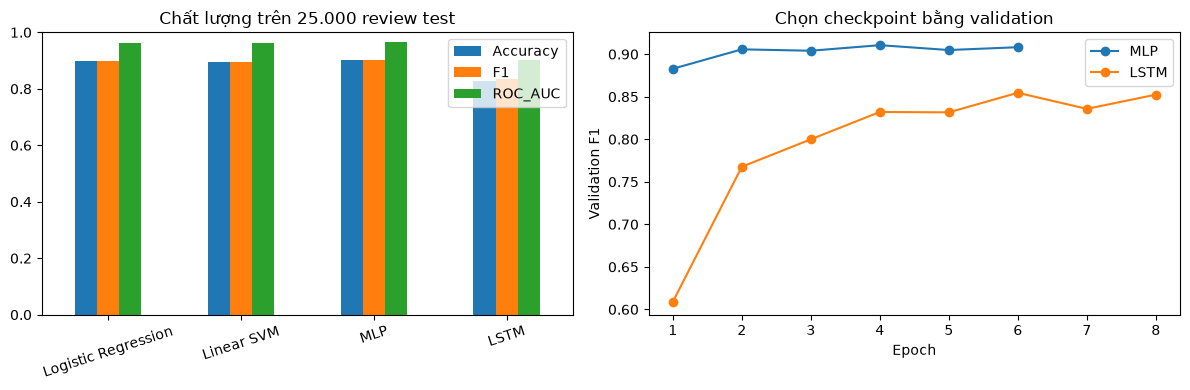

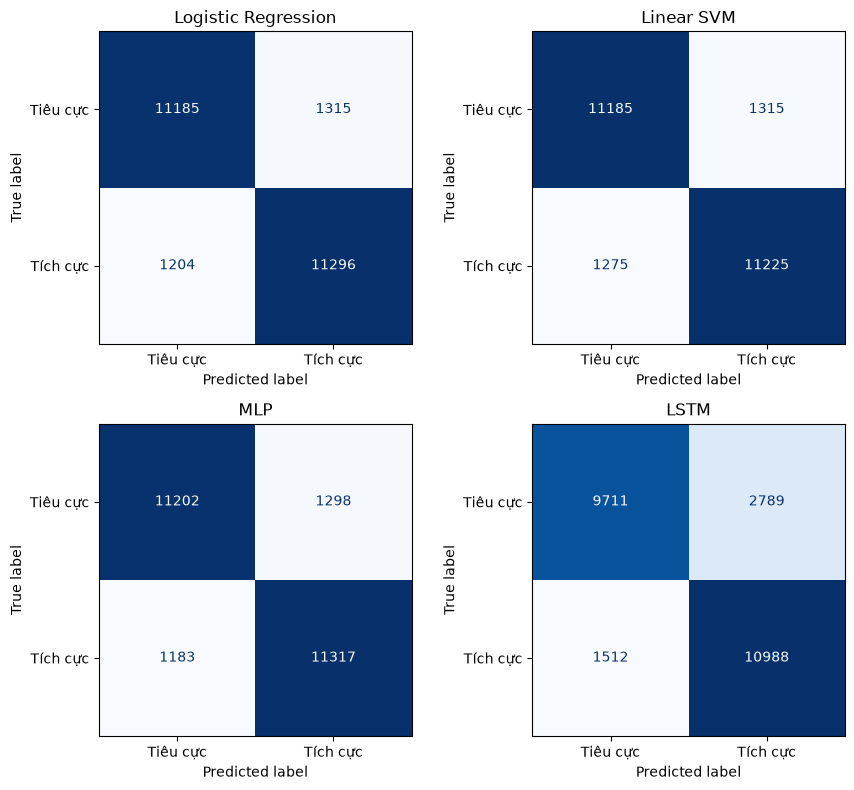


Logistic Regression
              precision    recall  f1-score   support

    Tiêu cực     0.9028    0.8948    0.8988     12500
    Tích cực     0.8957    0.9037    0.8997     12500

    accuracy                         0.8992     25000
   macro avg     0.8993    0.8992    0.8992     25000
weighted avg     0.8993    0.8992    0.8992     25000


Linear SVM
              precision    recall  f1-score   support

    Tiêu cực     0.8977    0.8948    0.8962     12500
    Tích cực     0.8951    0.8980    0.8966     12500

    accuracy                         0.8964     25000
   macro avg     0.8964    0.8964    0.8964     25000
weighted avg     0.8964    0.8964    0.8964     25000


MLP
              precision    recall  f1-score   support

    Tiêu cực     0.9045    0.8962    0.9003     12500
    Tích cực     0.8971    0.9054    0.9012     12500

    accuracy                         0.9008     25000
   macro avg     0.9008    0.9008    0.9008     25000
weighted avg     0.9008    0.9008   

In [7]:
fig,axes = plt.subplots(1,2,figsize=(12,4))
results[['Accuracy','F1','ROC_AUC']].plot.bar(ax=axes[0],ylim=(0,1),rot=18)
axes[0].set_title('Chất lượng trên 25.000 review test'); axes[0].set_xlabel('')
for name,hist in histories.items():
    axes[1].plot(hist.epoch,hist.validation_F1,marker='o',label=name)
axes[1].set(xlabel='Epoch',ylabel='Validation F1',title='Chọn checkpoint bằng validation')
axes[1].legend(); plt.tight_layout(); plt.savefig(OUT/'comparison.png',dpi=160); plt.show()
fig,axes = plt.subplots(2,2,figsize=(9,8))
for ax,(name,pred) in zip(axes.ravel(),predictions.items()):
    ConfusionMatrixDisplay.from_predictions(ytest,pred,display_labels=['Tiêu cực','Tích cực'],
                                            ax=ax,colorbar=False,cmap='Blues')
    ax.set_title(name)
plt.tight_layout(); plt.savefig(OUT/'confusion_matrices.png',dpi=160); plt.show()
for name,pred in predictions.items():
    print('\n'+name)
    print(classification_report(ytest,pred,target_names=['Tiêu cực','Tích cực'],digits=4))

## 5. Phân tích lỗi và độ không chắc chắn

Khoảng tin cậy 95% của chênh lệch accuracy LSTM với SVM được ước lượng bằng **paired bootstrap**, lấy mẫu lại cùng chỉ mục review cho hai mô hình (2.000 lần). Nếu khoảng chứa 0, thí nghiệm này chưa thể hiện rõ chênh lệch accuracy theo phép ước lượng đó. Bootstrap theo review không phản ánh biến thiên do khởi tạo mạng, chia train/validation hoặc các review cùng phim.

In [8]:
rng = np.random.default_rng(SEED)
diff = (predictions['LSTM']==ytest).astype(float)-(predictions['Linear SVM']==ytest).astype(float)
boot = np.array([rng.choice(diff,size=len(diff),replace=True).mean() for _ in range(2000)])
lo,hi = np.quantile(boot,[.025,.975])
print(f'Accuracy LSTM − SVM: {diff.mean():+.4f}; bootstrap 95% CI [{lo:+.4f}, {hi:+.4f}]')
wrong = np.flatnonzero(predictions['LSTM'] != ytest)
sample = rng.choice(wrong,size=min(6,len(wrong)),replace=False)
errors = test.iloc[sample][['id','clean','label']].copy()
errors['LSTM_prediction'] = predictions['LSTM'][sample]
errors['review_excerpt'] = errors.clean.str[:700]
display(errors[['id','review_excerpt','label','LSTM_prediction']].reset_index(drop=True))
errors.to_csv(OUT/'LSTM_error_examples.csv',index=False,encoding='utf-8-sig')

best = results.F1.idxmax()
lstm_f1,svm_f1 = results.loc['LSTM','F1'],results.loc['Linear SVM','F1']
display(Markdown(f"""### Nhận xét từ kết quả thực nghiệm

- Mô hình có test F1 cao nhất trong lần chạy: **{best}**, F1 **{results.loc[best,'F1']:.4f}**, accuracy **{results.loc[best,'Accuracy']:.4f}**. Đây là mô tả bảng kết quả, không dùng test để chỉnh mô hình.
- LSTM đạt F1 **{lstm_f1:.4f}**; SVM đạt **{svm_f1:.4f}**; chênh lệch F1 LSTM − SVM: **{lstm_f1-svm_f1:+.4f}**.
- LSTM mất **{fit_times['LSTM']:.1f} giây** huấn luyện trên **{DEVICE}**. TF–IDF chỉ cần nhận diện các từ/cụm từ mang cảm xúc; LSTM phải học cả embedding và cách tổng hợp chuỗi từ đầu.
- Có **{(lengths>MAX_LEN).mean():.1%}** review train dài hơn {MAX_LEN} token. Cắt đuôi có thể làm LSTM mất câu kết luận cảm xúc; TF–IDF sử dụng toàn văn nên có lợi thế thông tin đầu vào.
- Sai số có thể liên quan đến phủ định, mỉa mai, cảm xúc hỗn hợp hoặc nội dung bị cắt. Các khả năng này cần đối chiếu review đầy đủ, không thể khẳng định chỉ từ đoạn trích.

### Kết luận và hạn chế

Thí nghiệm so sánh LSTM, MLP, Logistic Regression và SVM trên cùng phân chia dữ liệu IMDB. Chỉ có một seed và một cấu hình kiến trúc cho mỗi mạng; chưa thể khái quát rằng một họ mô hình luôn tốt hơn họ còn lại. Chưa đánh giá khả năng tổng quát sang miền khác hoặc tiếng Việt.

Hướng cải thiện: thử độ dài 512 token, BiLSTM hoặc embedding tiền huấn luyện; mở rộng tìm kiếm siêu tham số theo validation; chạy nhiều seed và báo cáo trung bình ± độ lệch chuẩn. Mỗi mở rộng phải giữ test độc lập, tránh điều chỉnh dựa trên kết quả test đã xem.
"""))

Accuracy LSTM − SVM: -0.0684; bootstrap 95% CI [-0.0730, -0.0639]


,id,review_excerpt,label,LSTM_prediction
0,test/3385,"the incomparable paul naschy, horror film icon...",0,1
1,test/7716,"in 1970, feminists invaded the 'miss world' be...",0,1
2,test/18092,"first, don't be fooled by my family name. my m...",1,0
3,test/5883,a group of friends discover gold deep inside a...,0,1
4,test/2857,...and boy is the collision deafening. a femal...,0,1
5,test/12463,the first shiloh film was enjoyable by adults ...,0,1


### Nhận xét từ kết quả thực nghiệm

- Mô hình có test F1 cao nhất trong lần chạy: **MLP**, F1 **0.9012**, accuracy **0.9008**. Đây là mô tả bảng kết quả, không dùng test để chỉnh mô hình.
- LSTM đạt F1 **0.8363**; SVM đạt **0.8966**; chênh lệch F1 LSTM − SVM: **-0.0602**.
- LSTM mất **127.7 giây** huấn luyện trên **cpu**. TF–IDF chỉ cần nhận diện các từ/cụm từ mang cảm xúc; LSTM phải học cả embedding và cách tổng hợp chuỗi từ đầu.
- Có **29.1%** review train dài hơn 256 token. Cắt đuôi có thể làm LSTM mất câu kết luận cảm xúc; TF–IDF sử dụng toàn văn nên có lợi thế thông tin đầu vào.
- Sai số có thể liên quan đến phủ định, mỉa mai, cảm xúc hỗn hợp hoặc nội dung bị cắt. Các khả năng này cần đối chiếu review đầy đủ, không thể khẳng định chỉ từ đoạn trích.

### Kết luận và hạn chế

Thí nghiệm so sánh LSTM, MLP, Logistic Regression và SVM trên cùng phân chia dữ liệu IMDB. Chỉ có một seed và một cấu hình kiến trúc cho mỗi mạng; chưa thể khái quát rằng một họ mô hình luôn tốt hơn họ còn lại. Chưa đánh giá khả năng tổng quát sang miền khác hoặc tiếng Việt.

Hướng cải thiện: thử độ dài 512 token, BiLSTM hoặc embedding tiền huấn luyện; mở rộng tìm kiếm siêu tham số theo validation; chạy nhiều seed và báo cáo trung bình ± độ lệch chuẩn. Mỗi mở rộng phải giữ test độc lập, tránh điều chỉnh dựa trên kết quả test đã xem.


## 6. Dự đoán review mới

Ví dụ dưới đây minh họa cách dùng LSTM đã huấn luyện. Các câu ví dụ không thuộc bộ đánh giá; không dùng để báo cáo accuracy. Sigmoid chuyển logit thành xác suất mô hình, chưa được hiệu chuẩn.

In [9]:
def predict_lstm(reviews):
    cleaned = [clean_text(s) for s in reviews]
    seq,lens = encode(cleaned)
    logits = neural_scores(models['LSTM'],seq,lens)
    probs = torch.sigmoid(torch.tensor(logits)).numpy()
    return pd.DataFrame({'review':reviews,'P(positive)':probs,
                         'prediction':np.where(probs>=.5,'Tích cực','Tiêu cực')})
display(predict_lstm([
    'A wonderful movie with excellent acting and a moving story.',
    'This movie was boring, badly written and a waste of time.',
    'The actors were good, but the story was disappointing.'
]))
print('Các bảng, biểu đồ và thông tin lần chạy đã lưu tại:',OUT.as_posix())

,review,P(positive),prediction
0,A wonderful movie with excellent acting and a ...,0.933372,Tích cực
1,"This movie was boring, badly written and a was...",0.037214,Tiêu cực
2,"The actors were good, but the story was disapp...",0.198490,Tiêu cực


Các bảng, biểu đồ và thông tin lần chạy đã lưu tại: results
